# К08 · GoToObj

Агент в комнате должен подойти к одному предмету. Среда считает эпизод успешным, если в конце он смотрит на предмет


In [1]:
from collections import deque

import gymnasium as gym
from stable_baselines3 import PPO
import matplotlib.pyplot as plt
import minigrid
import numpy as np

ENV_ID = "BabyAI-GoToObj-v0"
BASE_SEED = 8
N_EPISODES = 15
PATH_FACTOR = 1.5
TRAIN_STEPS = 200_000
TRAIN_SEED = 0

# 0 вправо, 1 вниз, 2 влево, 3 вверх. Так же устроен MiniGrid.
DIRS = ((1, 0), (0, 1), (-1, 0), (0, -1))

COLOR_RGB = {
    "red": (0.85, 0.15, 0.15),
    "green": (0.15, 0.65, 0.25),
    "blue": (0.20, 0.35, 0.85),
    "purple": (0.55, 0.20, 0.70),
    "yellow": (0.90, 0.75, 0.10),
    "grey": (0.45, 0.45, 0.45),
}

env = gym.make(ENV_ID)


## 1. Среда

GoToObj: одна комната 8×8, без дверей и без посторонних предметов. Инструкция вида go to the yellow key. Объект один, его цвет и тип выбирает генератор уровня.

Успех для go-to в BabyAI наступает, когда агент стоит на соседней клетке и смотрит на объект. Отдельное действие done среда не требует. Лимит шагов среда ставит сама: для этого уровня это room_size² = 64. Награда за успех **1 - 0.9 * (шаг / лимит)**, за таймаут ноль.


go to the yellow key лимит 64


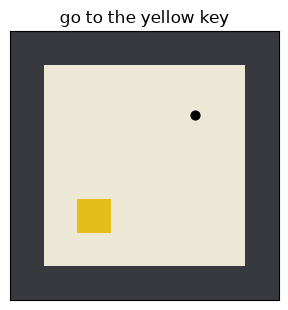

In [2]:
def static_map(env):
    grid = env.unwrapped.grid
    kind = np.zeros((grid.height, grid.width), dtype=np.uint8)  # 0 пол, 1 стена, 2 объект
    for x in range(grid.width):
        for y in range(grid.height):
            cell = grid.get(x, y)
            if cell is None:
                continue
            kind[y, x] = 1 if cell.type == "wall" else 2
    return kind


def room_rgb(kind, color_name):
    img = np.empty(kind.shape + (3,))
    img[:] = (0.93, 0.91, 0.84)
    img[kind == 1] = (0.22, 0.22, 0.25)
    img[kind == 2] = COLOR_RGB.get(color_name, (0.8, 0.2, 0.2))
    return img


obs, info = env.reset(seed=BASE_SEED)
u = env.unwrapped
obj = tuple(int(v) for v in u.instrs.desc.obj_poss[0])
obj_color = u.grid.get(*obj).color

print(u.mission, "лимит", u.max_steps)

fig, ax = plt.subplots(figsize=(3.2, 3.2))
ax.imshow(room_rgb(static_map(env), obj_color), origin="upper")
ax.scatter([u.agent_pos[0]], [u.agent_pos[1]], s=40, c="black")
ax.set_title(u.mission)
ax.set_xticks([])
ax.set_yticks([])
fig.tight_layout()
plt.show()


### 1.1. Карта и действия

Чёрная точка на картинке — агент в начале эпизода с сидом 8, цветная клетка — объект. Эта же карта ниже будет эпизодом 1, уже с обученным агентом.

Стены и объект непроходимы. Действия, которые крутим дальше: 0 налево, 1 направо, 2 вперёд. 


## 2. Кратчайший путь

Состояние в BFS — клетка и направление. Каждый поворот и каждый шаг вперёд стоят одно действие, упор в стену клетку не меняет.

Ищем кратчайшую последовательность, после которой клетка перед агентом совпадает с клеткой объекта. Это то же условие, по которому среда ставит успех. Длину считаем от старта эпизода, по карте до первого шага.

Ниже проверка на сиде 8: проходим найденный путь и смотрим, что среда закрывает эпизод ровно на последнем действии и даёт награду. Если числа не сойдутся, порог 1.5× дальше не к чему прикладывать.


In [3]:

def policy_obs(env):
    agent = env.unwrapped
    height, width = agent.grid.height, agent.grid.width
    ax, ay = int(agent.agent_pos[0]), int(agent.agent_pos[1])
    ox, oy = [int(v) for v in agent.instrs.desc.obj_poss[0]]
    direction = np.zeros(4, dtype=np.float32)
    direction[int(agent.agent_dir)] = 1
    relative = np.array([(ox - ax) / width, (oy - ay) / height], dtype=np.float32)
    return np.concatenate([relative, direction])


def blocked_cells(env):
    grid = env.unwrapped.grid
    blocked = set()
    for x in range(grid.width):
        for y in range(grid.height):
            if grid.get(x, y) is not None:
                blocked.add((x, y))
    return blocked


def move(state, action, blocked):
    x, y, direction = state
    if action == 0:
        return (x, y, (direction - 1) % 4)
    if action == 1:
        return (x, y, (direction + 1) % 4)
    dx, dy = DIRS[direction]
    nxt = (x + dx, y + dy)
    if nxt in blocked:
        return (x, y, direction)
    return (nxt[0], nxt[1], direction)


def facing_object(state, obj):
    x, y, direction = state
    dx, dy = DIRS[direction]
    return (x + dx, y + dy) == obj


def bfs_actions(start, blocked, obj):
    if facing_object(start, obj):
        for action in (2, 0, 1):
            if facing_object(move(start, action, blocked), obj):
                return [action]
        return None

    queue = deque([start])
    parent = {start: None}
    parent_action = {}
    found = None
    while queue:
        state = queue.popleft()
        for action in (0, 1, 2):
            nxt = move(state, action, blocked)
            if nxt in parent:
                continue
            parent[nxt] = state
            parent_action[nxt] = action
            if facing_object(nxt, obj):
                found = nxt
                queue.clear()
                break
            queue.append(nxt)
    if found is None:
        return None

    actions = []
    state = found
    while state != start:
        actions.append(parent_action[state])
        state = parent[state]
    actions.reverse()
    return actions


def run_episode(env, seed, policy):
    env.reset(seed=seed)
    u = env.unwrapped
    obj = tuple(int(v) for v in u.instrs.desc.obj_poss[0])
    obj_color = u.grid.get(*obj).color
    kind = static_map(env)
    start = (int(u.agent_pos[0]), int(u.agent_pos[1]), int(u.agent_dir))
    actions = bfs_actions(start, blocked_cells(env), obj)
    if not actions:
        raise RuntimeError(f"BFS не нашёл путь, сид {seed}")

    positions = [start]
    terminated = False
    truncated = False
    reward = 0.0

    def step(action):
        nonlocal reward, terminated, truncated
        _, reward, terminated, truncated, _ = env.step(int(action))
        agent = env.unwrapped
        positions.append((int(agent.agent_pos[0]), int(agent.agent_pos[1]), int(agent.agent_dir)))

    if policy == "bfs":
        for action in actions:
            step(action)
            if terminated or truncated:
                break
    elif policy == "ppo":
        obs = policy_obs(env)
        while not (terminated or truncated):
            action, _ = model.predict(obs, deterministic=True)
            step(int(action))
            obs = policy_obs(env)
    else:
        raise ValueError(policy)

    steps = int(env.unwrapped.step_count)
    reward = float(reward)
    optimal = len(actions)
    env_success = bool(terminated) and reward > 0
    return {
        "seed": seed,
        "mission": env.unwrapped.mission,
        "steps": steps,
        "max_steps": int(env.unwrapped.max_steps),
        "optimal": optimal,
        "limit": PATH_FACTOR * optimal,
        "ratio": steps / optimal,
        "terminated": bool(terminated),
        "truncated": bool(truncated),
        "reward": reward,
        "env_success": env_success,
        "alt_success": env_success and steps <= PATH_FACTOR * optimal,
        "positions": positions,
        "kind": kind,
        "obj_color": obj_color,
    }


check = run_episode(env, BASE_SEED, policy="bfs")
print(check["mission"], "bfs", check["optimal"], "шагов", check["steps"])
if check["steps"] != check["optimal"] or not check["env_success"]:
    raise RuntimeError("длина BFS не совпала с успехом среды")


go to the yellow key bfs 7 шагов 7


### 2.1. Проверка на сиде 8

На сиде 8 кратчайший путь находится, и среда считает его успехом. Эта проверка в таблицу 15 эпизодов не входит: там дальше только обученный агент.


## 3. 15 эпизодов

Агент — PPO, обученный на этом уровне: 200 000 шагов, сид 0. На каждом шаге он выбирает налево, направо или вперёд. Сеть видит, в какой стороне предмет и куда смотрит агент.

Номера эпизодов идут с 1 до 15. Эпизод n запускается с **seed = 8 + (n - 1)**. И карта, и действия от этого сида повторяются.


In [4]:
class GoToState(gym.Wrapper):
    def __init__(self, env):
        super().__init__(env)
        self.observation_space = gym.spaces.Box(-1, 1, (6,), dtype=np.float32)
        self.action_space = gym.spaces.Discrete(3)

    def reset(self, **kwargs):
        self.env.reset(**kwargs)
        return policy_obs(self.env), {}

    def step(self, action):
        action = int(np.asarray(action).reshape(-1)[0])
        _, reward, terminated, truncated, info = self.env.step(action)
        return policy_obs(self.env), float(reward), terminated, truncated, info


train_env = GoToState(gym.make(ENV_ID))
model = PPO(
    "MlpPolicy",
    train_env,
    seed=TRAIN_SEED,
    n_steps=512,
    batch_size=128,
    n_epochs=6,
    learning_rate=3e-4,
    ent_coef=0.005,
    gamma=0.99,
    policy_kwargs=dict(net_arch=[64, 64]),
    verbose=0,
    device="cpu",
)
model.learn(TRAIN_STEPS)

episodes = []
for n in range(1, N_EPISODES + 1):
    episode = run_episode(env, BASE_SEED + n - 1, policy="ppo")
    episode["episode"] = n
    episodes.append(episode)


### 3.1. Два сигнала

успех_среды — terminated и награда больше нуля.

успех_фильтра — успех среды и **шаги <= 1.5 * bfs**.

In [5]:
header = f"{'эп':>2}  {'инструкция':<22} {'шаги':>4} {'bfs':>3} {'отн':>6}  {'среда':>5} {'фильтр':>6}  trunc"
print(header)
print("-" * len(header))
for ep in episodes:
    print(
        f"{ep['episode']:>2}  {ep['mission']:<22} {ep['steps']:>4} {ep['optimal']:>3} "
        f"{ep['ratio']:>6.2f}  {('да' if ep['env_success'] else 'нет'):>5} "
        f"{('да' if ep['alt_success'] else 'нет'):>6}  {int(ep['truncated']):>5}"
    )


эп  инструкция             шаги bfs    отн  среда фильтр  trunc
---------------------------------------------------------------
 1  go to the yellow key      9   7   1.29     да     да      0
 2  go to the green key       2   2   1.00     да     да      0
 3  go to the red ball       10   7   1.43     да     да      0
 4  go to the grey ball       8   8   1.00     да     да      0
 5  go to the yellow key      5   4   1.25     да     да      0
 6  go to the red box        11  10   1.10     да     да      0
 7  go to the grey key       10   9   1.11     да     да      0
 8  go to the grey key        3   3   1.00     да     да      0
 9  go to the grey box        8   6   1.33     да     да      0
10  go to the blue ball       9   8   1.12     да     да      0
11  go to the green ball      5   4   1.25     да     да      0
12  go to the yellow ball     4   4   1.00     да     да      0
13  go to the blue key        5   4   1.25     да     да      0
14  go to the purple ball     8   8   1.

### 3.2. Маршруты

Серое — стены, цветная клетка — объект. Клетки пола темнее там, где агент дольше стоял: повороты на месте на линии не видны, а в закраске видны. Линия — порядок хода, кружок — старт, стрелка — финальный взгляд. В заголовке: успех среды, фильтр, число шагов и BFS.


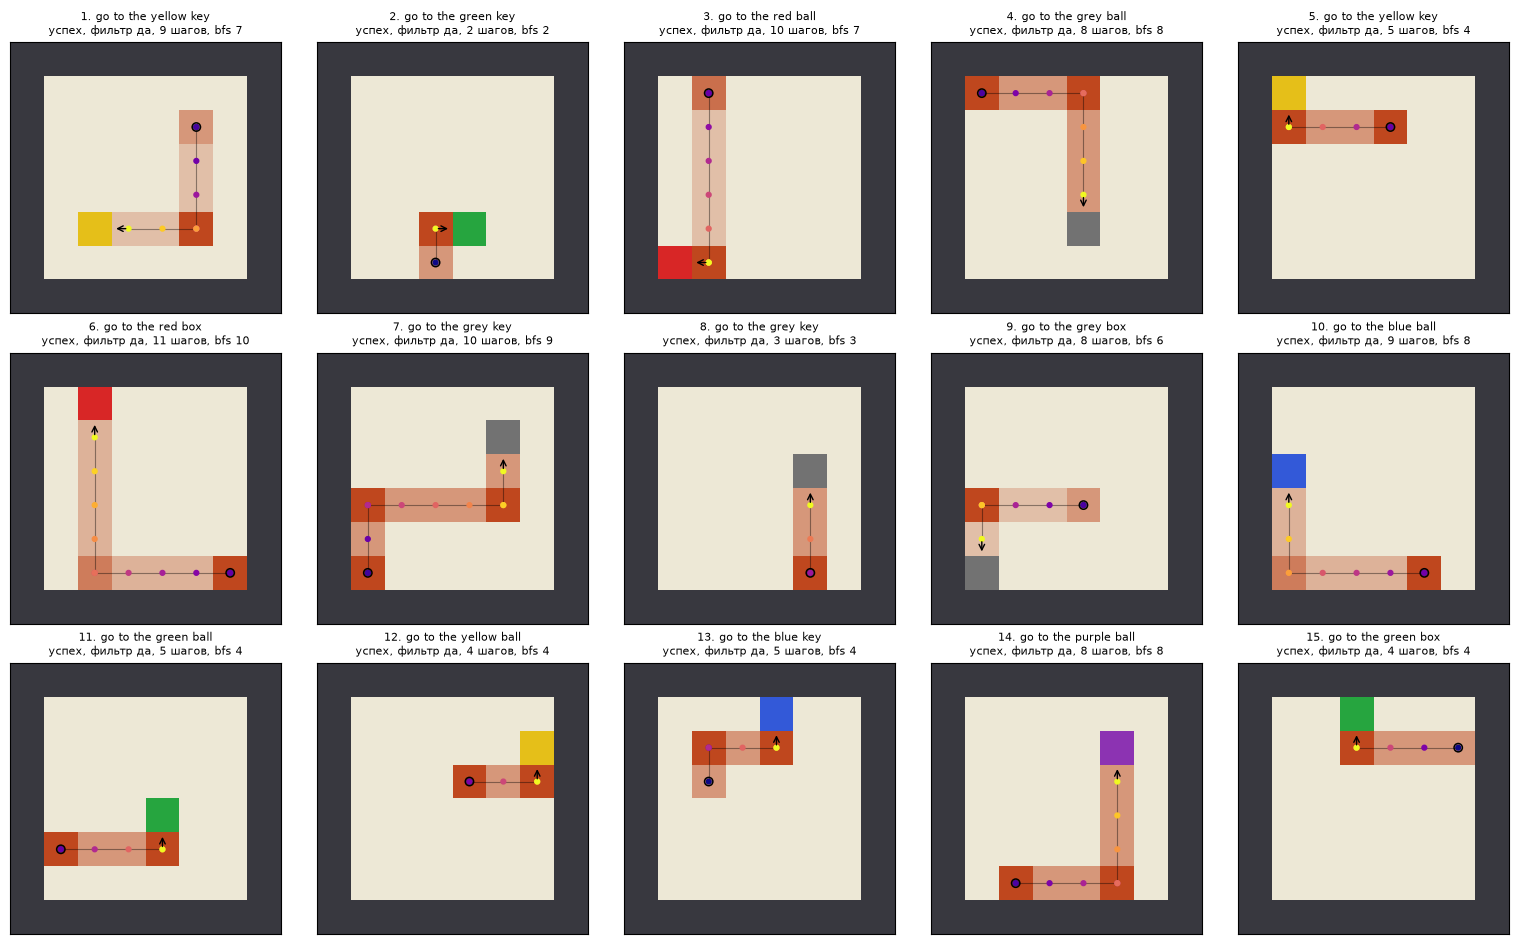

In [6]:
def draw_paths(title_fn):
    fig, axes = plt.subplots(3, 5, figsize=(15.5, 9.5))
    for ax, ep in zip(axes.ravel(), episodes):
        img = room_rgb(ep["kind"], ep["obj_color"])
        visits = np.zeros(ep["kind"].shape, dtype=float)
        for x, y, _ in ep["positions"]:
            visits[y, x] += 1
        floor = ep["kind"] == 0
        if visits.max() > 0:
            heat = (visits / visits.max())[floor, None]
            img[floor] = (1 - heat) * img[floor] + heat * np.array([0.75, 0.28, 0.12])
        ax.imshow(img, origin="upper")
        xs = [p[0] for p in ep["positions"]]
        ys = [p[1] for p in ep["positions"]]
        ax.plot(xs, ys, color="black", linewidth=0.8, alpha=0.4)
        ax.scatter(xs, ys, c=np.arange(len(xs)), cmap="plasma", s=12, zorder=3)
        ax.scatter([xs[0]], [ys[0]], s=36, facecolors="none", edgecolors="black", linewidths=1.1, zorder=4)
        x, y, direction = ep["positions"][-1]
        dx, dy = DIRS[direction]
        ax.annotate(
            "",
            xy=(x + 0.45 * dx, y + 0.45 * dy),
            xytext=(x, y),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.0),
        )
        ax.set_title(title_fn(ep), fontsize=8)
        h, w = ep["kind"].shape
        ax.set_xlim(-0.5, w - 0.5)
        ax.set_ylim(h - 0.5, -0.5)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.tight_layout()
    plt.show()


def title_with_scores(ep):
    if ep["env_success"] and ep["alt_success"]:
        status = "успех, фильтр да"
    elif ep["env_success"]:
        status = "успех, фильтр нет"
    else:
        status = "таймаут"
    return f"{ep['episode']}. {ep['mission']}\n{status}, {ep['steps']} шагов, bfs {ep['optimal']}"


draw_paths(title_with_scores)


In [7]:
LABELS = {
    1: "осмысленно",
    2: "осмысленно",
    3: "осмысленно",
    4: "осмысленно",
    5: "осмысленно",
    6: "осмысленно",
    7: "осмысленно",
    8: "осмысленно",
    9: "осмысленно",
    10: "осмысленно",
    11: "осмысленно",
    12: "осмысленно",
    13: "осмысленно",
    14: "осмысленно",
    15: "осмысленно",
}


def ratio_text(num, den, undefined):
    if den == 0:
        return undefined
    return f"{num}/{den} = {num / den:.3f}"


def confusion(pred_key, joined_rows):
    tp = fp = fn = tn = 0
    for row in joined_rows:
        pred = int(row[pred_key]) == 1
        human = row["метка"] == "осмысленно"
        if pred and human:
            tp += 1
        elif pred and not human:
            fp += 1
        elif (not pred) and human:
            fn += 1
        else:
            tn += 1
    return tp, fp, fn, tn


missing = [ep["episode"] for ep in episodes if ep["episode"] not in LABELS]
if missing:
    raise RuntimeError(f"нет метки для эпизодов: {missing}")

joined = []
for ep in episodes:
    joined.append({
        "эпизод": ep["episode"],
        "seed": ep["seed"],
        "успех_среды": int(ep["env_success"]),
        "успех_фильтра": int(ep["alt_success"]),
        "метка": LABELS[ep["episode"]],
    })
labeled = joined

print(f"{'эп':>2}  {'среда':>5} {'фильтр':>6}  метка")
for item in joined:
    label = item["метка"] if item["метка"] else "—"
    print(f"{item['эпизод']:>2}  {item['успех_среды']:>5} {item['успех_фильтра']:>6}  {label}")
print()

undefined_rate = "не определена: знаменатель равен нулю, положительных ответов оценщика нет"
undefined_recall = "не определена: в разметке нет «осмысленно»"

for title, key in (("сигнал среды", "успех_среды"), ("фильтр 1.5× BFS", "успех_фильтра")):
    tp, fp, fn, tn = confusion(key, labeled)
    total = tp + fp + fn + tn
    print(title)
    print("ложных успехов:", fp, " доля:", ratio_text(fp, tp + fp, undefined_rate))
    print(f"совпадений: {tp + tn}/{total}")
    print(f"матрица: {tp} {fp} / {fn} {tn}")
    print("precision:", ratio_text(tp, tp + fp, undefined_rate))
    print("recall:", ratio_text(tp, tp + fn, undefined_recall))
    print()

assert len(episodes) == N_EPISODES == 15
assert [ep["episode"] for ep in episodes] == list(range(1, 16))
assert PATH_FACTOR == 1.5
assert ENV_ID == "BabyAI-GoToObj-v0"
assert BASE_SEED == 8

again = [run_episode(env, BASE_SEED + n - 1, policy="ppo") for n in range(1, N_EPISODES + 1)]
for first, second in zip(episodes, again):
    assert first["steps"] == second["steps"]
    assert first["optimal"] == second["optimal"]
    assert first["mission"] == second["mission"]
    assert first["env_success"] == second["env_success"]
    assert first["alt_success"] == second["alt_success"]
    assert first["terminated"] == second["terminated"]
    assert first["truncated"] == second["truncated"]
    assert first["reward"] == second["reward"]
    assert first["positions"] == second["positions"]

bfs_again = run_episode(env, BASE_SEED, policy="bfs")
assert bfs_again["env_success"]
assert bfs_again["steps"] == bfs_again["optimal"]
assert bfs_again["steps"] == check["steps"]
assert bfs_again["reward"] == check["reward"]

for row in joined:
    episode_id = int(row["эпизод"])
    assert int(row["seed"]) == BASE_SEED + episode_id - 1
    assert row["метка"] == LABELS[episode_id]


эп  среда фильтр  метка
 1      1      1  осмысленно
 2      1      1  осмысленно
 3      1      1  осмысленно
 4      1      1  осмысленно
 5      1      1  осмысленно
 6      1      1  осмысленно
 7      1      1  осмысленно
 8      1      1  осмысленно
 9      1      1  осмысленно
10      1      1  осмысленно
11      1      1  осмысленно
12      1      1  осмысленно
13      1      1  осмысленно
14      1      1  осмысленно
15      1      1  осмысленно

сигнал среды
ложных успехов: 0  доля: 0/15 = 0.000
совпадений: 15/15
матрица: 15 0 / 0 0
precision: 15/15 = 1.000
recall: 15/15 = 1.000

фильтр 1.5× BFS
ложных успехов: 0  доля: 0/15 = 0.000
совпадений: 15/15
матрица: 15 0 / 0 0
precision: 15/15 = 1.000
recall: 15/15 = 1.000



## 4. Что получилось

Проверка BFS на сиде 8 сошлась со средой: до жёлтого ключа 7 шагов, terminated, награда 0.902. На той же карте обученный агент (эпизод 1) дошёл за 9 шагов, bfs 7.

Из 15 эпизодов успех среды во всех. Фильтр 1.5× BFS тоже пропустил все. Эпизод 1 — сид 8, эпизод 15 — сид 22.

По картинкам маршруты короткие. Дальше всех от оптимума эпизод 3: 10 шагов при bfs 7, отношение 1.43. Эпизод 9: 8 шагов при bfs 6. Таймаутов нет.

### 4.1. Результаты пилота

«Осмысленно»: 1–15.

Среда. Ложных успехов 0/15. Совпадений 15/15. Precision 15/15, recall 15/15.

| | осмысленно | неосмысленно |
| --- | --- | --- |
| успех 1 | 15 | 0 |
| успех 0 | 0 | 0 |

Фильтр. Ложных успехов 0/15. Совпадений 15/15. Precision 15/15, recall 15/15.

| | осмысленно | неосмысленно |
| --- | --- | --- |
| фильтр 1 | 15 | 0 |
| фильтр 0 | 0 | 0 |

Совпадений поровну, 15/15. Оба сигнала на каждом эпизоде отвечают успехом.
